In [1]:
import torch.nn.functional as F
import torch
import matplotlib.pyplot as plt

In [2]:
names = open('names.txt', 'r').read().splitlines()

In [3]:
len(names)

32033

In [4]:
chars = sorted(list(set(''.join(names))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)

In [5]:
# build dataset
block_size = 3
def build_dataset(names):
    X, Y = [], []
    for w in names:
        context = [0]*block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]
    
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X,Y

import random
random.seed(42)
random.shuffle(names)
n1 = int(0.8*len(names))
n2 = int(0.9*len(names))
Xtr, Ytr = build_dataset(names[:n1])
Xdev, Ydev = build_dataset(names[n1:n2])
Xte, Yte = build_dataset(names[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [6]:
class Linear:
    def __init__(self, fan_in, fan_out, g, bias=True):
        self.weights = torch.randn([fan_in, fan_out], generator=g)/fan_in**0.5
        self.bias = torch.zeros(fan_out) if bias is True else None

    def __call__(self, x):
        self.out = x @ self.weights
        if self.bias is not None:
            self.out += self.bias
        return self.out

    def parameters(self):
        self.parameters = [self.weights] + ([] if self.bias is None else [self.bias])
        return self.parameters


class BatchNorm1D:
    def __init__(self, dim, eps=1e-5, momentum=0.1):
        self.eps = eps
        self.momentum = momentum
        self.training = True

        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)

        self.running_mean = torch.zeros([1, dim])
        self.running_var = torch.ones([1, dim])

    def __call__(self, x):

        if self.training:
            xmean = x.mean(0, keepdim=True)
            xvar = x.var(0, keepdim=True)
        else:
            xmean = self.running_mean
            xvar = self.running_var

        xhat = (x - xmean)/torch.sqrt(xvar + self.eps)
        self.out = self.gamma*xhat + self.beta

        if self.training:
            with torch.no_grad():
                self.running_mean = (1-self.momentum)*self.running_mean + self.momentum*xmean
                self.running_var = (1-self.momentum)*self.running_var + self.momentum*xvar
        return self.out

    def parameters(self):
        return [self.gamma, self.beta]


class Tanh:

    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out

    def parameters(self):
        return []

In [7]:
n_embd = 10
n_hidden = 200
block_size = 3
batch_size = 32
g = torch.Generator().manual_seed(123456)
C = torch.randn([vocab_size, n_embd])
layers = [
    Linear(n_embd*block_size, n_hidden, g, bias=False), BatchNorm1D(n_hidden), Tanh(),
    Linear(        n_hidden, n_hidden, g, bias=False), BatchNorm1D(n_hidden), Tanh(),
    Linear(        n_hidden, n_hidden, g, bias=False), BatchNorm1D(n_hidden), Tanh(),
    Linear(        n_hidden, n_hidden, g, bias=False), BatchNorm1D(n_hidden), Tanh(),
    Linear(        n_hidden, n_hidden, g, bias=False), BatchNorm1D(n_hidden), Tanh(),
    Linear(        n_hidden, vocab_size, g), BatchNorm1D(vocab_size)
]

with torch.no_grad():
    layers[-1].gamma *- 0.1

    for layer in layers[:-1]:
        if isinstance(layer, Linear):
            layer.weights *= 1.0

parameters = [C] + [p for layer in layers for p in layer.parameters()]
for p in parameters:
    p.requires_grad = True

print(sum(p.nelement() for p in parameters))

173751


In [ ]:
max_steps = 200000
lossi = []
ud = []

for i in range(max_steps):
    #mini batch
    ix = torch.randint(0, Xtr.shape[0], (batch_size, ), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix]

    #forward pass
    emb = C[Xb]
    x = emb.view(emb.shape[0], -1)
    for layer in layers:
        x = layer(x)
    loss = F.cross_entropy(x, Yb)
    
    #backward pass
    for layer in layers:
        layer.out.retain_grad()
    for p in parameters:
        p.grad = None

    loss.backward()

    #gradient updates
    lr = 0.1 if i<150000 else 0.01
    for p in parameters:
        p.data += -lr*p.grad

    #telemetry
    if i%10000 == 0:
        print(f'{i:7d}/{max_steps:7d}: {loss.item(): .4f}')
    lossi.append(loss.log10().item())
    with torch.no_grad():
        ud.append([((lr*p.grad).std()/p.data.std()).log10().item() for p in parameters])

      0/ 200000:  3.9781
  10000/ 200000:  2.2093
  20000/ 200000:  2.1389
  30000/ 200000:  1.8966
  40000/ 200000:  2.0103
  50000/ 200000:  2.0998
  60000/ 200000:  2.2219
  70000/ 200000:  2.3463
  80000/ 200000:  2.6213
  90000/ 200000:  1.9196
 100000/ 200000:  2.2189
 110000/ 200000:  2.3873
 120000/ 200000:  2.0561
 130000/ 200000:  1.8797
 140000/ 200000:  2.2823
 150000/ 200000:  1.9126
 160000/ 200000:  2.2515


In [ ]:
plt.figure(figsize=(20, 4))
for i, layer in enumerate(layers[:-1]):
    if isinstance(layer, Tanh):
        t = layer.out
        print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, layer.__class__.__name__, t.mean(), t.std(), (t.abs() > 0.97).float().mean()*100))
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f'layer {i} {layer.__class__.__name__}')
    plt.legend(legends)
    plt.title('activation distribution')

layer 2 (      Tanh): mean +0.00, std 1.361080e-03
layer 5 (      Tanh): mean -0.00, std 1.183491e-03
layer 8 (      Tanh): mean -0.00, std 1.134898e-03
layer 11 (      Tanh): mean -0.00, std 1.055723e-03
layer 14 (      Tanh): mean +0.00, std 1.109296e-03


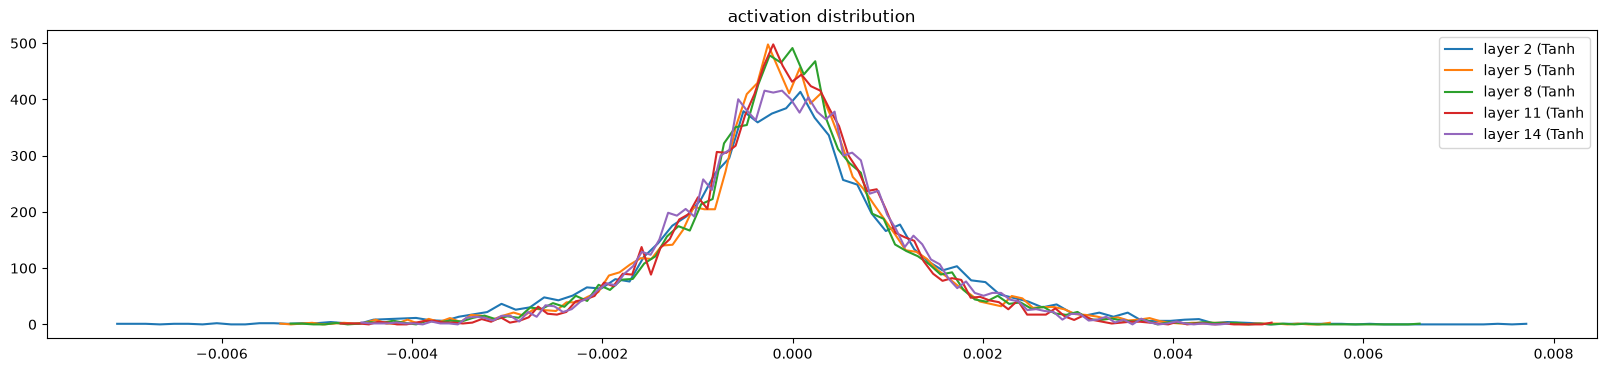

In [71]:
plt.figure(figsize=(20, 4))
for i, layer in enumerate(layers[:-1]):
    if isinstance(layer, Tanh):
        t = layer.out.grad
        print('layer %d (%10s): mean %+.2f, std %e' % (i, layer.__class__.__name__, t.mean(), t.std()))
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f'layer {i} {layer.__class__.__name__}')
    plt.legend(legends)
    plt.title('activation distribution')

weight   (27, 10) | mean +0.000000 | std 8.005466e-03 | grad:data ratio 8.133111e-03
weight  (30, 200) | mean -0.000149 | std 5.592723e-03 | grad:data ratio 3.074205e-02
weight (200, 200) | mean -0.000020 | std 3.926288e-03 | grad:data ratio 5.461755e-02
weight (200, 200) | mean +0.000011 | std 3.368318e-03 | grad:data ratio 4.704246e-02
weight (200, 200) | mean -0.000021 | std 3.176047e-03 | grad:data ratio 4.405354e-02
weight (200, 200) | mean -0.000010 | std 2.975589e-03 | grad:data ratio 4.133424e-02
weight  (200, 27) | mean +0.000119 | std 8.666533e-03 | grad:data ratio 1.116820e-01


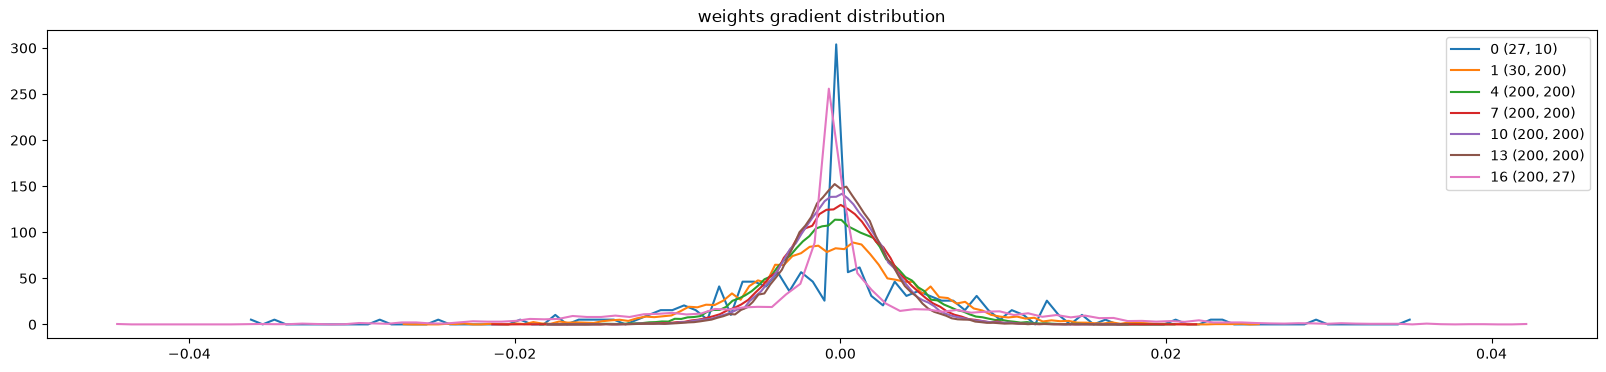

In [72]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i,p in enumerate(parameters):
  t = p.grad
  if p.ndim == 2:
    print('weight %10s | mean %+f | std %e | grad:data ratio %e' % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'{i} {tuple(p.shape)}')
plt.legend(legends)
plt.title('weights gradient distribution');

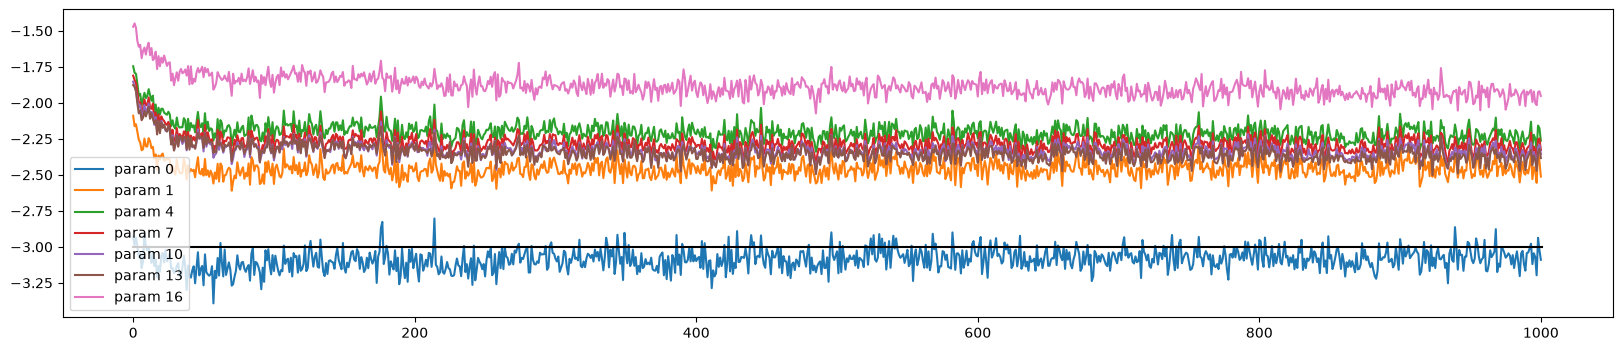

In [73]:
plt.figure(figsize=(20, 4))
legends = []
for i,p in enumerate(parameters):
  if p.ndim == 2:
    plt.plot([ud[j][i] for j in range(len(ud))])
    legends.append('param %d' % i)
plt.plot([0, len(ud)], [-3, -3], 'k') # these ratios should be ~1e-3, indicate on plot
plt.legend(legends);

In [74]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (XVal, YVal),
    'test': (Xte, Yte),
  }[split]
  emb = C[x] # (N, block_size, n_embd)
  x = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  for layer in layers:
    x = layer(x)
  loss = F.cross_entropy(x, y)
  print(split, loss.item())

# put layers into eval mode
for layer in layers:
  layer.training = False
split_loss('train')
split_loss('val')

NameError: name 'running_mean' is not defined